In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve

# Modelo Preditivo: Falha de Porta de Plataforma nos Próximos 7 Dias

## O problema

As Portas de Plataforma (PSDs) das estações de metrô operam em ciclos intensivos de abertura e fechamento, e falham — travam, param de abrir, perdem comunicação. Quando isso acontece, a manutenção corretiva age depois do fato: alguém percebe o problema (ou o CCO recebe um alarme), abre uma ordem de serviço, e uma equipe vai até a estação consertar.

A pergunta deste notebook é se dá para inverter essa lógica: **usando o histórico de manutenções e alarmes de uma estação, dá para prever que ela vai ter uma falha nos próximos 7 dias, antes de ela acontecer?** Se der, a equipe de manutenção pode agir de forma preventiva em vez de reativa — inspecionar, ajustar, trocar uma peça com desgaste visível, antes que a porta pare de funcionar de vez.

## Os dados

Quatro fontes, cada uma capturando um ângulo diferente da operação:

- **Alarmes** — o sistema de PSD registra automaticamente qualquer anomalia (obstrução, falha de comunicação, sensor destravado, etc.), com estação, porta e horário. É o "pulso" da operação, em tempo quase real.
- **Corretiva Emergencial (ZM01) e Corretiva Programada (ZM02)** — as ordens de manutenção efetivamente abertas depois de uma falha, com data, estação, sintoma, causa e ação tomada. É a variável que queremos prever: quando e onde a próxima falha acontece.
- **Preventiva (ZM03)** — manutenção agendada (não motivada por falha), como troca de ar-condicionado do rack ou inspeção de rotina.

## O caminho até o modelo

O notebook segue uma sequência de decisões, cada uma construída em cima da anterior:

1. **Carregar e limpar os dados**, decidindo o que entra e o que fica de fora da análise.
2. **Construir features** que resumem o histórico de cada estação até um dado momento `T` — sempre olhando só para o passado, nunca para o futuro (senão o modelo "trapaceia").
3. **Definir o alvo**: `falha_proximos_7d`, se a próxima manutenção da estação acontece dentro de 7 dias.
4. **Treinar e avaliar um XGBoost**, com atenção especial a um problema que domina este dataset: o desbalanceamento extremo entre estações que vão falhar em breve e as que não vão.
5. **Diagnosticar o resultado** com espírito crítico — overfitting, qualidade do rótulo, o que as features realmente carregam de sinal.

O fio condutor é honestidade sobre o que os dados permitem concluir. Vários caminhos testados ao longo do desenvolvimento (ajuste de threshold, features adicionais, junção de outras bases) não melhoraram o resultado e foram descartados — o que também é uma conclusão válida, e ajuda a entender os limites reais desse problema com os dados disponíveis hoje.

## 1. Carregamento dos Dados

O ponto de partida são as quatro bases já limpas por etapas anteriores do projeto (`_limpa`/`_limpo`, sem os problemas de formatação da exportação bruta do SAP). A decisão de juntar `ZM01` (emergencial) e `ZM02` (programada) num único `zm01` já acontece aqui, na carga: as duas são "manutenção corretiva" — a diferença entre elas é só a urgência com que a ordem foi tratada, não o tipo de evento. Como o alvo do modelo (`falha_proximos_7d = 0`, estação sem falha na semana seguinte) é uma classe rara, cada linha extra de corretiva ajuda a enxergar melhor os poucos casos "sem falha" que existem no meio de milhares de "com falha".

In [2]:
alarmes = pd.read_csv('../../data/Alarmes/alarmes_trata_limpos_consolidado.csv')
zm01 = pd.read_excel('../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx', sheet_name='ZM01_limpa')
zm02 = pd.read_excel('../../data/Corretiva Programada/processados/ZM02_limpa.xlsx', sheet_name='ZM02_limpa')
zm03 = pd.read_csv('../../data/Preventiva/preventiva_zm03_limpa.csv')

print(alarmes.shape, zm01.shape, zm02.shape, zm03.shape)

# Une corretiva emergencial (zm01) e programada (zm02) num único dataframe de manutenções,
# para ter mais exemplos (principalmente da classe rara falha_proximos_7d = 0). As duas
# planilhas têm o mesmo esquema de colunas; `tipo_de_nota` (Z1 = emergencial, Z2 = programada)
# preserva a origem de cada linha. O restante do notebook usa `zm01` sem alterações.
zm01 = pd.concat([zm01, zm02], ignore_index=True, sort=False)
print(f"\nZM01 (emergencial) + ZM02 (programada) unidos: {zm01.shape}")
print(zm01['tipo_de_nota'].value_counts())

(742506, 15) (10543, 27) (1163, 27) (569, 19)

ZM01 (emergencial) + ZM02 (programada) unidos: (11706, 30)
tipo_de_nota
Z1    10543
Z2     1163
Name: count, dtype: int64


Uma primeira olhada nos alarmes mostra a granularidade que eles trazem: TAG do equipamento, estação, número da porta, tipo de alarme e os dois horários (disparo e normalização) que permitem calcular quanto tempo a anomalia durou. `numeroAlarmesEstacao` — quantos alarmes cada estação acumulou no total — é calculado aqui porque vira, mais adiante, a primeira feature do modelo: um proxy simples de quão "barulhenta" (e potencialmente exigida) é cada estação.

In [3]:
alarmes.head(5)

numeroAlarmesEstacao = alarmes['Estação'].value_counts()

## 2. Pré-Processamento

Antes de qualquer feature, os dados precisam estar em um formato que permita comparar eventos no tempo e cruzar estações entre as bases. Duas coisas resolvidas aqui: transformar texto em datetime (sem isso, nada de "quantos dias desde a última manutenção" é possível) e decidir o que conta como um alarme "real" versus ruído.

### Transformando em Datetime

`T` (o horário de início da avaria) é a coluna mais importante deste notebook inteiro — praticamente toda feature depois daqui é "o que aconteceu antes de `T`, na mesma estação". Errar esse parsing propaga erro para tudo o mais.

In [4]:
zm01["T"] = pd.to_datetime(zm01["inicio_avaria_datetime"], errors="coerce")
zm01['fim_avaria_datetime'] = pd.to_datetime(zm01['fim_avaria_datetime'], errors='coerce')
alarmes['Horário do Alarme'] = pd.to_datetime(alarmes['Horário do Alarme'], errors='coerce')
alarmes['dt_alarme'] = pd.to_datetime(alarmes['dt_alarme'], errors='coerce')
alarmes['dt_normalizacao'] = pd.to_datetime(alarmes['dt_normalizacao'], errors='coerce')
alarmes.head(5)

,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização,tempo_normalizacao_seg,dt_alarme,dt_normalizacao,duracao_calculada_seg,estacao_extraida,plataforma_extraida,porta_extraida,tipo_evento_extraido
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01",1,2026-05-12 08:16:52.657,2026-05-12 08:16:53.670,1.013,FAL,FAL2,9.0,OBS
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01",1,2026-05-12 08:15:09.913,2026-05-12 08:15:10.917,1.004,LUZ,LUZ1,8.0,OBS
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01",1,2026-05-12 08:14:06.657,2026-05-12 08:14:07.670,1.013,FAL,FAL1,15.0,OBS
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01",1,2026-05-12 08:09:31.930,2026-05-12 08:09:32.917,0.987,LUZ,LUZ1,19.0,OBS
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09",9,2026-05-12 08:05:05.830,2026-05-12 08:05:14.847,9.017,FRE,FRE1,14.0,OBS


### Filtrando Ruído: Alarmes de Obstrução Muito Curtos

Nem todo alarme `OBS` (obstrução) representa um problema real na porta. Uma mochila que fica presa por um segundo e é liberada não é sinal de degradação mecânica — é o comportamento normal e esperado de uma porta de plataforma em uma estação cheia. Alarmes `OBS` com duração menor que 30 segundos são descartados por essa razão: eles adicionariam volume aos dados sem adicionar sinal, diluindo o efeito de alarmes que de fato indicam algo errado com o equipamento.

In [5]:
# 1. Calcula a duração em segundos (caso ainda não tenha essa coluna)
zm01['estacao'] = zm01['local_de_instalacao'].str.extract(r'PSD-([A-Z0-9]+)')
alarmes["duracao_segundos"] = (
    alarmes["dt_normalizacao"] - alarmes["dt_alarme"]
).dt.total_seconds()

# 2. Identifica os alarmes de OBS com menos de 30s
obs_curto = alarmes["Alarme"].astype(str).str.contains(
    "OBS", case=False, na=False
) & (alarmes["duracao_segundos"] < 30)

# 3. Mantém apenas os alarmes válidos na tabela
alarmes = alarmes[~obs_curto].reset_index(drop=True)

zm01.head(5)

,linha_origem,tipo_de_nota,nota,ordem,perfil_do_catalogo,descricao,local_de_instalacao,centro_de_trabalho_responsavel,inicio_avaria_datetime,fim_avaria_datetime,...,sintoma,objeto,defeito,causa,acao,nota_repetida_flag,duracao_extrema_flag,duracao_zero_flag,T,estacao
0,2,Z1,14943931,53954586.0,6PSD,PSD PL 01-02 Sem status para o CCO,SP04-6-PSD-BUT,SP04IBUT,2025-11-14 06:35:28,NaT,...,LAÇO DE PDM ABERTO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-11-14 06:35:28,BUT
1,3,Z1,15133619,54145839.0,6PSD,PSD - PDM's não abriram PLT02,SP04-6-PSD-BUT,SP04IBUT,2026-02-27 07:33:00,2026-02-27 12:00:00,...,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO,RESETADO E TESTADO,NaN,NaN,NaN,2026-02-27 07:33:00,BUT
2,4,Z1,13894133,52913343.0,6PSD,PSD server s/ status das plataformas,SP04-6-PSD-BUT-P1S1,SP04IBUT,2024-04-18 06:00:00,2024-04-18 07:30:00,...,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE,RESETADO E TESTADO,NaN,NaN,NaN,2024-04-18 06:00:00,BUT
3,5,Z1,14713349,53724958.0,6PSD,BUT PLT 1 PORTAS NAO ABRIRAM,SP04-6-PSD-BUT-P1S1,SP04IBUT,2025-07-07 18:38:00,2025-07-08 03:00:00,...,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE,RESETADO E TESTADO,NaN,NaN,NaN,2025-07-07 18:38:00,BUT
4,6,Z1,14643768,53655728.0,6PSD,PSD plt 1 - Falha geral de abertura,SP04-6-PSD-BUT-P1S1-PSSE1,SP04IBUT,2025-05-28 09:10:00,2025-05-28 10:00:00,...,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC,RESETADO E TESTADO,NaN,NaN,NaN,2025-05-28 09:10:00,BUT


Com o alarme filtrado, falta uma última organização antes das features: ordenar cada base por estação e por tempo. Toda a lógica de "olhar para trás no tempo" que vem a seguir (histórico de manutenções, contagem de alarmes recentes) depende de percorrer os eventos em ordem cronológica dentro de cada estação — sem essa ordenação, um `shift()` ou uma busca binária por janela de tempo simplesmente não fazem sentido.

In [6]:
# Ordena os DataFrames por estação e tempo
zm01 = zm01.sort_values(["estacao", "T"]).reset_index(drop=True)
alarmes = (
    alarmes.sort_values(["Estação", "dt_alarme"])
    .dropna(subset=["dt_alarme"])
    .reset_index(drop=True)
)

## 3. Features

Toda feature construída aqui segue a mesma regra: **só pode usar informação que já existia no momento `T`**. Isso pode parecer óbvio, mas é fácil quebrar por acidente — por exemplo, calcular a duração média de todas as manutenções de uma estação (incluindo a atual) contaminaria a feature com informação do próprio evento que se está tentando prever. Por isso praticamente todo cálculo abaixo usa `shift(1)`, `cumcount()` ou uma busca binária limitada ao passado: a feature representa o que um mantenedor saberia, olhando o histórico da estação, exatamente antes daquele momento — nunca depois.

As primeiras features vêm de uma intuição simples de manutenção preditiva: uma porta que está prestes a falhar normalmente já vem "avisando" — mais alarmes, manutenções mais recorrentes, reparos mais demorados. As seções seguintes constroem esses sinais e, mais adiante no notebook, testam se eles realmente carregam esse aviso.

### Identidade e Exposição da Estação

`estacao` é extraída do campo `local_de_instalacao` e vira a chave usada em praticamente todo o resto do notebook para juntar informação entre bases diferentes (manutenção, alarme, preventiva). `numero_alarmes` é a feature mais simples possível: o total histórico de alarmes daquela estação, um proxy bruto de "quanto essa estação é usada e monitorada" — estações maiores/mais movimentadas tendem a acumular mais alarmes só pelo volume de operação, independente de estarem degradando ou não.

In [7]:
# Feature - Nome da estação
zm01['estacao'] = zm01['local_de_instalacao'].str.extract(r'PSD-([A-Z0-9]+)')

In [8]:
# Feature - Numero de Alarmes por Estação
zm01['numero_alarmes'] = zm01['estacao'].map(numeroAlarmesEstacao).fillna(0).astype(int)

### Alarmes Antes da Manutenção

`alarmes_antes_manu` conta, por busca binária num vetor de horários ordenado (bem mais rápido que filtrar o dataframe inteiro a cada linha), quantos alarmes já haviam acontecido em todo o sistema até o fim daquela avaria. É uma feature mais bruta que as janelas de tempo construídas a seguir — mede volume acumulado, não recência —, mas serve de base para comparar com as versões mais refinadas.

In [9]:
# Feature - Alarmes Antes Manutencao

datas_alarmes_ordenadas = (
    alarmes["Horário do Alarme"].dropna().sort_values().values
)

total_alarmes = len(datas_alarmes_ordenadas)

zm01["alarmes_antes_manu"] = np.searchsorted(
    datas_alarmes_ordenadas, zm01["fim_avaria_datetime"].values, side="left"
)
zm01.loc[zm01["fim_avaria_datetime"].isna(), "alarmes_antes_manu"] = 0

### Dias Desde a Última Manutenção

Aqui entra a primeira feature de "tempo desde o último evento": `shift(1)` dentro de cada grupo de estação pega o fim da manutenção anterior, e a diferença para `T` vira `dias_desde_ultima_manutencao`. A intuição é dupla e ambígua de propósito — um intervalo curto pode indicar uma porta que "não fica boa" (mesmo problema voltando rápido), e um intervalo longo pode indicar acúmulo de desgaste natural. Estações na primeira manutenção do seu histórico (sem evento anterior) recebem `-1` como sentinela, para não confundir "nunca teve manutenção antes" com "teve manutenção há zero dias".

In [10]:
# 1. Feature: dias_desde_ultima_manutencao
zm01["ultima_manu_fim"] = zm01.groupby("estacao")["fim_avaria_datetime"].shift(1)
zm01["dias_desde_ultima_manutencao"] = (zm01["T"] - zm01["ultima_manu_fim"]).dt.total_seconds() / 86400.0
zm01["dias_desde_ultima_manutencao"] = zm01["dias_desde_ultima_manutencao"].fillna(-1)

### Janelas de Alarme: 24h, 7 Dias e Tendência

Esta é a feature mais diretamente ligada à ideia de "aviso antes da falha": quantos alarmes a estação teve nas últimas 24 horas e nos últimos 7 dias, sempre antes de `T`. `calcular_janelas` faz isso de forma eficiente — para cada estação, ordena os horários de alarme uma vez e usa três buscas binárias (`searchsorted`) por evento de manutenção, em vez de varrer a base de alarmes inteira a cada linha, o que seria proibitivamente lento com centenas de milhares de registros.

`tendencia_alarmes` combina as duas janelas numa única razão: alarmes das últimas 24h divididos pela média diária dos últimos 7 dias. Um valor bem acima de 1 significa "hoje está mais barulhento que o normal recente daquela estação" — uma tentativa de capturar não só o volume de alarme, mas se ele está *acelerando*, o sinal mais parecido com "a porta está piorando agora".

In [11]:
def calcular_janelas(df_zm, df_alt):
    cnt_24h = np.zeros(len(df_zm), dtype=int)
    cnt_7d = np.zeros(len(df_zm), dtype=int)

    for estacao, grp_zm in df_zm.groupby("estacao"):
        grp_alt = df_alt[df_alt["Estação"] == estacao]
        if grp_alt.empty:
            continue

        # Converte explicitamente para array nativo datetime64[ns] do NumPy (Evita o TypeError)
        times_alt = grp_alt["dt_alarme"].to_numpy(dtype="datetime64[ns]")
        times_zm = grp_zm["T"].to_numpy(dtype="datetime64[ns]")

        idx_t = np.searchsorted(times_alt, times_zm, side="right")
        idx_24h = np.searchsorted(
            times_alt, times_zm - np.timedelta64(24, "h"), side="left"
        )
        idx_7d = np.searchsorted(
            times_alt, times_zm - np.timedelta64(7, "D"), side="left"
        )

        cnt_24h[grp_zm.index] = idx_t - idx_24h
        cnt_7d[grp_zm.index] = idx_t - idx_7d

    return cnt_24h, cnt_7d

In [12]:
zm01["alarmes_ultimas_24h"], zm01["alarmes_ultimos_7d"] = calcular_janelas(zm01, alarmes)

media_diaria_7d = zm01["alarmes_ultimos_7d"] / 7.0
zm01["tendencia_alarmes"] = np.where(media_diaria_7d > 0, zm01["alarmes_ultimas_24h"] / media_diaria_7d, 0.0)

zm01['tendencia_alarmes'].value_counts()

tendencia_alarmes
0.000000    5706
7.000000      72
1.925784      24
0.176554      24
1.995098      23
            ... 
0.478632       1
0.663793       1
4.693798       1
4.569444       1
1.857516       1
Name: count, Length: 4835, dtype: int64

### Novas Features (guiadas pelo gráfico de importância e pelo mapa de correlação)

As features desta seção nasceram de uma segunda passada pelo notebook: depois de rodar o modelo com o conjunto inicial e olhar a importância de cada variável e o mapa de correlação (ambos mais adiante), ficou claro que faltava capturar o **histórico de reincidência** da estação de forma mais direta — não só "quando foi a última vez", mas "quantas vezes isso já aconteceu" e "isso costuma demorar para consertar".

- `numero_manutencoes_anteriores`: quantas manutenções a estação já teve antes desta (histórico de reincidência).
- `duracao_media_manutencoes_anteriores`: duração média (em horas) das manutenções anteriores da estação — usa `shift(1)` para não vazar a duração da própria ocorrência atual.
- `dia_semana` e `mes`: sazonalidade da manutenção, extraídos de `T`.

In [13]:
# Feature - Número de manutenções anteriores na estação (conta só o passado, sem vazamento)
zm01["numero_manutencoes_anteriores"] = zm01.groupby("estacao").cumcount()

# Feature - Duração média das manutenções anteriores na estação
zm01["duracao_media_manutencoes_anteriores"] = zm01.groupby("estacao")["duracao_avaria_horas"].transform(
    lambda s: s.shift(1).expanding().mean()
)
zm01["duracao_media_manutencoes_anteriores"] = zm01["duracao_media_manutencoes_anteriores"].fillna(0)

# Feature - Sazonalidade
zm01["dia_semana"] = zm01["T"].dt.dayofweek
zm01["mes"] = zm01["T"].dt.month

### Feature - Manutenção Preventiva (ZM03)

A preventiva (zm03) não entra na timeline que define o alvo `falha_proximos_7d` — ela é manutenção agendada, não uma falha, e misturá-la ali contaminaria o rótulo (uma visita agendada sem problema nenhum passaria a contar como "falha chegando"). Em vez disso, ela entra como **feature**, do mesmo jeito que os alarmes já entram (`alarmes_ultimas_24h`, `alarmes_ultimos_7d`):

- `dias_desde_ultima_preventiva`: há quanto tempo a estação teve a última preventiva antes de `T` (histórico).
- `preventivas_agendadas_prox_7d`: quantas preventivas já estão agendadas para os próximos 7 dias a partir de `T` — informação legítima de se ter no momento da previsão, já que manutenção preventiva é agendada com antecedência.

Eventos cancelados (`cancelada == True`) são descartados por não terem ocorrido de fato.</cell id="9e8b5c58">


In [14]:
zm03_validas = zm03[~zm03["cancelada"]].copy()
zm03_validas["DT_Inicio"] = pd.to_datetime(zm03_validas["DT_Inicio"], errors="coerce")
zm03_validas = zm03_validas.dropna(subset=["DT_Inicio", "Estacao"])


def calcular_features_preventiva(df_zm, df_prev):
    dias_desde_preventiva = np.full(len(df_zm), -1.0)
    preventivas_prox_7d = np.zeros(len(df_zm), dtype=int)

    for estacao, grp_zm in df_zm.groupby("estacao"):
        grp_prev = df_prev[df_prev["Estacao"] == estacao].sort_values("DT_Inicio")
        if grp_prev.empty:
            continue

        times_prev = grp_prev["DT_Inicio"].to_numpy(dtype="datetime64[ns]")
        times_zm = grp_zm["T"].to_numpy(dtype="datetime64[ns]")

        # Nº de preventivas antes de T (usado tanto p/ "última antes" quanto p/ o intervalo seguinte)
        idx_antes = np.searchsorted(times_prev, times_zm, side="left")

        tem_anterior = idx_antes > 0
        dias = np.full(len(times_zm), -1.0)
        if tem_anterior.any():
            deltas = (times_zm[tem_anterior] - times_prev[idx_antes[tem_anterior] - 1]) / np.timedelta64(1, "D")
            dias[tem_anterior] = deltas
        dias_desde_preventiva[grp_zm.index] = dias

        # Preventivas agendadas em (T, T+7d]
        idx_ate_7d = np.searchsorted(times_prev, times_zm + np.timedelta64(7, "D"), side="right")
        preventivas_prox_7d[grp_zm.index] = idx_ate_7d - idx_antes

    return dias_desde_preventiva, preventivas_prox_7d


zm01["dias_desde_ultima_preventiva"], zm01["preventivas_agendadas_prox_7d"] = calcular_features_preventiva(
    zm01, zm03_validas
)

print(f"Preventivas válidas (não canceladas): {len(zm03_validas)} de {len(zm03)}")
print(zm01[["dias_desde_ultima_preventiva", "preventivas_agendadas_prox_7d"]].describe())

Preventivas válidas (não canceladas): 559 de 569
       dias_desde_ultima_preventiva  preventivas_agendadas_prox_7d
count                  11706.000000                   11706.000000
mean                      29.392706                       0.253203
std                       24.298090                       0.618489
min                       -1.000000                       0.000000
25%                        9.153698                       0.000000
50%                       22.118924                       0.000000
75%                       47.254878                       0.000000
max                       97.785417                       3.000000


## 4. Transformações de Variáveis Categóricas

Com todas as features numéricas prontas, falta lidar com o texto: `estacao`, `sintoma`, `objeto` e `defeito` são categóricas, e o XGBoost precisa de números. Antes de decidir como codificar, vale olhar os tipos de cada coluna para confirmar que tudo o que foi criado até aqui está no formato esperado (datas como datetime, contagens como inteiro, etc.).

In [15]:
zm01.dtypes

linha_origem                                     int64
tipo_de_nota                                       str
nota                                             int64
ordem                                          float64
perfil_do_catalogo                                 str
descricao                                          str
local_de_instalacao                                str
centro_de_trabalho_responsavel                     str
inicio_avaria_datetime                  datetime64[us]
fim_avaria_datetime                     datetime64[us]
duracao_avaria_horas                           float64
analise_datetime                        datetime64[us]
encerramento_datetime                   datetime64[us]
indisponivel_flag                                 bool
falha_flag                                      object
analisada_flag                                    bool
ordem_ausente_flag                                bool
ordem_repetida_flag                               bool
comentario

### Label Encoder

A escolha é `LabelEncoder` (cada categoria vira um inteiro) em vez de one-hot encoding. Para um modelo baseado em árvores como o XGBoost isso não é um problema — a árvore não assume nenhuma ordem ou distância entre os códigos, só aprende a dividir por eles — e evita explodir o número de colunas com variáveis de alta cardinalidade como `defeito` e `sintoma`, que têm dezenas de categorias distintas. Os encoders de cada coluna são guardados em `label_encoders` para que, se necessário, o código original (o texto) possa ser recuperado a partir do número mais tarde.

In [16]:
colunas_categoricas = [
    "estacao",
    "defeito",
    "sintoma",
    "objeto",
]

label_encoders = {}

for col in colunas_categoricas:
    le = LabelEncoder()
    zm01[col] = le.fit_transform(zm01[col].astype(str))
    label_encoders[col] = le

zm01.head(5)

,linha_origem,tipo_de_nota,nota,ordem,perfil_do_catalogo,descricao,local_de_instalacao,centro_de_trabalho_responsavel,inicio_avaria_datetime,fim_avaria_datetime,...,dias_desde_ultima_manutencao,alarmes_ultimas_24h,alarmes_ultimos_7d,tendencia_alarmes,numero_manutencoes_anteriores,duracao_media_manutencoes_anteriores,dia_semana,mes,dias_desde_ultima_preventiva,preventivas_agendadas_prox_7d
0,33,Z2,13036981,52078709.0,6PSD,Led apagado,SP04-6-PSD-BUT-PLT2-PP18PDM,SP04IBUT,2023-01-03 03:55:59,2023-01-20 02:00:00,...,-1.000000,0,0,0.0,0,0.000000,1,1,-1.0,0
1,683,Z1,13036932,52078677.0,6PSD,PDM 18 - Falha de fechamento,SP04-6-PSD-BUT-PLT2-PP18PDM,SP04IBUT,2023-01-03 04:18:00,2023-01-03 04:48:16,...,-16.904167,0,0,0.0,1,406.066944,1,1,-1.0,0
2,533,Z1,13038801,52080470.0,6PSD,PDM 07 Falha na abertura,SP04-6-PSD-BUT-PLT2-PP07PDM,SP04IBUT,2023-01-04 06:30:00,2023-01-04 07:00:00,...,1.070648,0,0,0.0,2,203.285694,2,1,-1.0,0
3,615,Z1,13045687,52086918.0,6PSD,PDM11 - Falha no fechamento,SP04-6-PSD-BUT-PLT2-PP11PDM,SP04IBUT,2023-01-08 10:25:00,2023-01-08 15:00:13,...,4.142361,0,0,0.0,3,135.690463,6,1,-1.0,0
4,115,Z1,13052087,52093262.0,6PSD,PDM 09 - Falha de fechamento,SP04-6-PSD-BUT-PLT1-PP09PDM,SP04IBUT,2023-01-11 18:18:00,2023-01-12 04:47:05,...,3.137350,0,0,0.0,4,102.914583,2,1,-1.0,0


## 5. Separando Dados de Teste e Treino

Duas decisões acontecem juntas nesta seção, e as duas moldam tudo o que vem depois: **como o alvo é definido** e **como os dados são divididos**.

### Como nasce o alvo `falha_proximos_7d`

A pergunta de negócio ("essa estação vai falhar em breve?") vira uma coluna assim: para cada evento de manutenção, olha-se qual é o *próximo* evento da mesma estação (`groupby("estacao")["T"].shift(-1)`) e quantos dias faltam até lá. Se for 7 dias ou menos, `falha_proximos_7d = 1`; senão, `0`. A última manutenção de cada estação não tem um "próximo evento" para comparar, então essas linhas são descartadas (`dropna`) — não há como rotulá-las.

O resultado dessa definição é o que dá o tom para o resto do notebook: `falha_proximos_7d = 1` em praticamente todos os casos (98,85%). Isso acontece porque, olhando o histórico completo, a maioria das manutenções de uma estação realmente é seguida por outra dentro de uma semana — falhas tendem a se agrupar no tempo. A classe rara, `0` (estação que passou 7 dias tranquila depois de uma manutenção), é justamente a mais interessante do ponto de vista prático — é o que separa "problema resolvido" de "vai quebrar de novo" — mas também a mais difícil de aprender, por ter poucos exemplos.

### Por que separar por tempo, e não aleatoriamente

O corte de treino/teste é feito no percentil 80 da data `T`, não com uma amostragem aleatória. A razão é simular a situação real de uso do modelo: no dia a dia, ele vai prever o futuro a partir do passado, nunca o contrário. Um split aleatório deixaria eventos do "futuro" vazarem para o treino, o modelo aprenderia padrões que não estariam disponíveis no momento da previsão real, e a métrica de teste ficaria artificialmente otimista. Cortar por data mantém o teste honesto: o modelo só vê o passado (80% mais antigo) para tentar prever um período que, na prática, ele nunca viu (os 20% mais recentes).

In [17]:
zm01 = zm01.sort_values(["estacao", "T"]).reset_index(drop=True)

zm01["proxima_avaria_datetime"] = zm01.groupby("estacao")["T"].shift(-1)

zm01["dias_ate_proxima_falha"] = (
    zm01["proxima_avaria_datetime"] - zm01["T"]
).dt.total_seconds() / 86400.0

zm01["falha_proximos_7d"] = (zm01["dias_ate_proxima_falha"] <= 7.0).astype(int)

df_modelo = zm01.dropna(subset=["dias_ate_proxima_falha"]).copy()

print(df_modelo["falha_proximos_7d"].value_counts())

falha_proximos_7d
1    11504
0      190
Name: count, dtype: int64


### Escolhendo as Features

Nem toda coluna construída até aqui entra no modelo. A lista final (`colunas_features`) é o resultado de uma limpeza: colunas constantes não ajudam a separar nada (`perfil_do_catalogo` tinha importância zero), colunas redundantes só adicionam ruído sem informação nova (`centro_de_trabalho_responsavel` tem 0,99 de correlação com `estacao` — são quase a mesma coisa escrita de duas formas), e colunas com importância zero no modelo treinado foram removidas para simplificar. Essa lista não foi decidida de uma vez só — é o resultado de rodar o modelo, olhar a importância e a correlação (seções mais à frente) e vir aqui ajustar, um ciclo que se repete conforme o notebook evolui.

In [18]:
# Removidas: perfil_do_catalogo (constante, importância 0), centro_de_trabalho_responsavel
# (corr. 0.99 com estacao, redundante), analisada_flag/ordem_ausente_flag/ordem_repetida_flag
# (importância 0 no modelo treinado).
colunas_features = [
    "dias_desde_ultima_manutencao",
    "alarmes_ultimas_24h",
    "alarmes_ultimos_7d",
    "tendencia_alarmes",
    "estacao",
    "sintoma",
    "objeto",
    "defeito",
    "indisponivel_flag",
    "numero_manutencoes_anteriores",
    "duracao_media_manutencoes_anteriores",
    "dia_semana",
    "mes",
    "dias_desde_ultima_preventiva",
    "preventivas_agendadas_prox_7d",
]

coluna_target = "falha_proximos_7d"

In [19]:
df_modelo = df_modelo.sort_values("T").reset_index(drop=True)

ponto_corte = df_modelo["T"].quantile(0.80)

treino_df = df_modelo[df_modelo["T"] < ponto_corte]
teste_df = df_modelo[df_modelo["T"] >= ponto_corte]

X_train = treino_df[colunas_features]
y_train = treino_df[coluna_target]

X_test = teste_df[colunas_features]
y_test = teste_df[coluna_target]

## 6. Treinando o Modelo: XGBoost sob Desbalanceamento Extremo

Com treino e teste separados, o próximo passo é escolher e ajustar o modelo. Duas decisões guiam esta seção:

**Por que XGBoost.** É um modelo baseado em árvores de decisão, o que combina bem com o tipo de feature que foi construído: contagens, razões e categorias codificadas como inteiro, sem exigir normalização e lidando naturalmente com relações não-lineares (ex.: "3 manutenções recentes" pode importar muito mais que "2", mas não na mesma proporção que "6" versus "5"). Também tem suporte nativo a `scale_pos_weight`, o que importa muito aqui.

**Por que isso importa: o desbalanceamento.** Como visto na seção anterior, 98,85% dos exemplos são da classe `1`. Um modelo "preguiçoso" que sempre prevê `1` já acerta quase 99% das vezes — essa é a barra de comparação (`baseline_majoritaria`), e é isso que torna a acurácia comum uma métrica enganosa aqui. Por isso:

- **`scoring="balanced_accuracy"`** na busca: essa métrica tira a média do recall das duas classes sem pesar pelo tamanho de cada uma, então um modelo que só acerta a classe majoritária pontua mal, mesmo tendo "acurácia" alta. É a métrica que de fato mede se o modelo aprendeu algo sobre a classe rara.
- **`scale_pos_weight` na grade de busca**, incluindo o valor `1` (sem reponderação nenhuma) ao lado da proporção real do desbalanceamento e do dobro dela — para deixar a própria busca decidir, com dados, se vale a pena forçar mais atenção à classe rara ou se isso atrapalha mais do que ajuda.
- **`RandomizedSearchCV`** em vez de testar a grade inteira: com 3×3×3×3×3×3 combinações possíveis, uma busca exaustiva seria cara computacionalmente para um ganho marginal; amostrar 25 combinações aleatórias cobre o espaço de forma razoável a um custo bem menor.

O resultado desta célula é o primeiro número real do notebook — e é onde a dificuldade do problema aparece de forma concreta: a classe `0` (sem falha em 7 dias) tem precisão e recall baixos, mesmo depois de toda essa reponderação.

In [20]:
# 1. Calculando a proporção real de desbalanceamento no treino
qtd_0 = (y_train == 0).sum()
qtd_1 = (y_train == 1).sum()
peso_desbalanceamento = (
    qtd_0 / qtd_1
)  # Como a classe 0 é a minoria, ajustamos o peso

# 2. Configura a grade. Inclui scale_pos_weight=1 (sem reponderação) para o
# search poder comparar de verdade se vale a pena forçar o balanceamento.
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "scale_pos_weight": [1, peso_desbalanceamento, peso_desbalanceamento * 2],
}

xgb = XGBClassifier(random_state=42, eval_metric="logloss")

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)

# 3. Avaliação
melhor_xgb = search.best_estimator_
y_pred = melhor_xgb.predict(X_test)

baseline_majoritaria = max(y_test.mean(), 1 - y_test.mean())

print(f"Baseline (sempre prever a classe majoritária): {baseline_majoritaria:.2%}")
print(f"Acurácia:            {accuracy_score(y_test, y_pred):.2%}")
print(f"Acurácia balanceada: {balanced_accuracy_score(y_test, y_pred):.2%}  <- métrica geral correta aqui")
print(f"Precisão (weighted): {precision_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print(f"Recall   (weighted): {recall_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print(f"F1       (weighted): {f1_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print()
print(classification_report(y_test, y_pred, zero_division=0))

Baseline (sempre prever a classe majoritária): 98.85%
Acurácia:            92.95%
Acurácia balanceada: 59.83%  <- métrica geral correta aqui
Precisão (weighted): 97.99%
Recall   (weighted): 92.95%
F1       (weighted): 95.31%

              precision    recall  f1-score   support

           0       0.05      0.26      0.08        27
           1       0.99      0.94      0.96      2312

    accuracy                           0.93      2339
   macro avg       0.52      0.60      0.52      2339
weighted avg       0.98      0.93      0.95      2339



## 7. Diagnóstico: Overfitting vs. Desbalanceamento

O número de teste sozinho não diz *por que* o modelo tem dificuldade com a classe rara. Podem ser duas coisas bem diferentes, que pedem soluções opostas:

- **Overfitting de verdade**: o modelo decorou padrões específicos dos 163 exemplos de classe `0` no treino, que não se repetem nos 27 exemplos de teste — nesse caso, ele teria desempenho ótimo no treino e ruim no teste, e a solução seria simplificar o modelo (menos profundidade, mais regularização).
- **Desbalanceamento estrutural**: mesmo sem decorar nada, existe tão pouco exemplo da classe rara e tão pouca separação real nas features que nenhum modelo aprenderia essa classe direito — nesse caso, o problema não é o modelo, é a quantidade e a qualidade de dado disponível, e simplificar o modelo só pioraria as coisas.

Comparar as métricas de treino e de teste lado a lado é o jeito mais direto de distinguir os dois cenários: desempenho parecido nos dois lados indica que o modelo generaliza (o problema é falta de sinal, não overfitting); treino muito melhor que teste indica overfitting de verdade.

In [21]:
y_pred_train = melhor_xgb.predict(X_train)


def imprime_metricas_gerais(y_true, y_pred, titulo):
    baseline = max(y_true.mean(), 1 - y_true.mean())
    print(f"=== {titulo} ===")
    print(f"Baseline (classe majoritária): {baseline:.2%}")
    print(f"Acurácia:            {accuracy_score(y_true, y_pred):.2%}")
    print(f"Acurácia balanceada: {balanced_accuracy_score(y_true, y_pred):.2%}")
    print(f"Precisão (weighted): {precision_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"Recall   (weighted): {recall_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"F1       (weighted): {f1_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(classification_report(y_true, y_pred, zero_division=0))


imprime_metricas_gerais(y_train, y_pred_train, "TREINO")
imprime_metricas_gerais(y_test, y_pred, "TESTE")

# Desempenho parecido entre treino e teste => o modelo generaliza (não é overfitting).
# Treino muito melhor que teste => overfitting de verdade.
# Acurácia abaixo do baseline => o balanceamento forçado está custando mais do que ajudando.

=== TREINO ===
Baseline (classe majoritária): 98.26%
Acurácia:            79.01%
Acurácia balanceada: 77.57%
Precisão (weighted): 97.84%
Recall   (weighted): 79.01%
F1       (weighted): 86.76%
              precision    recall  f1-score   support

           0       0.06      0.76      0.11       163
           1       0.99      0.79      0.88      9192

    accuracy                           0.79      9355
   macro avg       0.53      0.78      0.50      9355
weighted avg       0.98      0.79      0.87      9355

=== TESTE ===
Baseline (classe majoritária): 98.85%
Acurácia:            92.95%
Acurácia balanceada: 59.83%
Precisão (weighted): 97.99%
Recall   (weighted): 92.95%
F1       (weighted): 95.31%
              precision    recall  f1-score   support

           0       0.05      0.26      0.08        27
           1       0.99      0.94      0.96      2312

    accuracy                           0.93      2339
   macro avg       0.52      0.60      0.52      2339
weighted avg    

## 8. Colocando em Dúvida o Próprio Rótulo

O diagnóstico anterior mostrou uma queda real de treino para teste — sinal de que o modelo generaliza mal, mas não necessariamente por decorar demais. Antes de tentar mais ajuste de modelo, vale desconfiar de uma fonte mais básica de ruído: será que toda linha rotulada como "falha nos próximos 7 dias" representa uma falha *nova*, ou parte disso é a mesma falha sendo reaberta — o mesmo chamado, o mesmo problema, registrado de novo porque o primeiro reparo não resolveu de fato?

Se uma fatia relevante das manutenções "seguintes" for na verdade reincidência do mesmo problema em vez de um evento novo e independente, isso infla artificialmente a classe `1` e definição do alvo fica menos confiável do que parece. A checagem abaixo olha para a fração de falhas cuja "próxima" ocorre em menos de 1 hora, 1 dia e 2 dias, e cruza com a flag `ordem_repetida_flag` que o SAP já usa para marcar retrabalho.

In [22]:
# Verifica se falhas "muito próximas" (minutos/horas) estão inflando o dataset,
# o que indicaria reabertura/duplicata de chamado em vez de uma nova falha real.
for limite in [1 / 24, 1, 2]:  # 1h, 1 dia, 2 dias
    frac = (df_modelo["dias_ate_proxima_falha"] < limite).mean()
    print(f"% de falhas com a próxima ocorrendo em menos de {limite:.4f} dia(s): {frac:.1%}")

print()
print(pd.crosstab(df_modelo["dias_ate_proxima_falha"] < 1, df_modelo["ordem_repetida_flag"], normalize="index"))

% de falhas com a próxima ocorrendo em menos de 0.0417 dia(s): 17.7%
% de falhas com a próxima ocorrendo em menos de 1.0000 dia(s): 66.2%
% de falhas com a próxima ocorrendo em menos de 2.0000 dia(s): 82.2%

ordem_repetida_flag        False     True 
dias_ate_proxima_falha                    
False                   0.992919  0.007081
True                    0.984755  0.015245


O quadro que aparece é ambíguo, não conclusivo: 66% das falhas têm a "próxima" em menos de 1 dia, e mesmo assim a flag `ordem_repetida_flag` do SAP marca reincidência em uma fração pequena desses casos (1,5% contra 0,7% quando o intervalo é maior). Ou seja, a maior parte dessa proximidade temporal não está sendo sinalizada pelo sistema como retrabalho — pode ser reincidência real não capturada pela flag, ou pode ser o comportamento genuíno do equipamento (uma porta com múltiplos problemas raramente falha só uma vez seguida). Sem um critério mais confiável para separar as duas coisas, a definição original do alvo é mantida, mas essa incerteza é um limite real do que os dados atuais permitem concluir com segurança.

## 9. Importância das Features

Com o modelo treinado e diagnosticado, cabe perguntar: o que ele está realmente usando para decidir? Esse gráfico tem dois papéis no notebook. Primeiro, interpretabilidade — para uma equipe de manutenção confiar (ou desconfiar) de uma previsão, ajuda saber que fatores pesam mais. Segundo, e é por isso que ele aparece tantas vezes citado nas seções anteriores: é a bússola usada para decidir que novas features valia a pena tentar (a seção "Novas Features", por exemplo, nasceu diretamente de uma rodada anterior deste gráfico) e quais colunas cortar da lista por não contribuírem em nada.

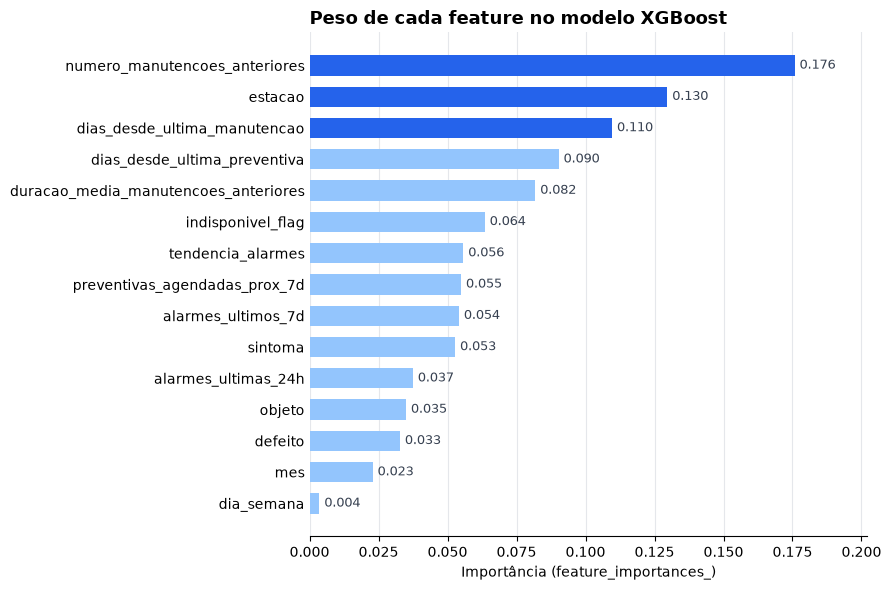

In [23]:
importancias = pd.Series(melhor_xgb.feature_importances_, index=colunas_features)
importancias = importancias.sort_values(ascending=True)

cor_base = "#93c5fd"
cor_destaque = "#2563eb"
n_destaque = 3
cores = [cor_destaque if i >= len(importancias) - n_destaque else cor_base for i in range(len(importancias))]

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(importancias.index, importancias.values, color=cores, height=0.65)

for barra, valor in zip(barras, importancias.values):
    ax.text(valor + importancias.max() * 0.01, barra.get_y() + barra.get_height() / 2,
             f"{valor:.3f}", va="center", ha="left", fontsize=9, color="#374151")

ax.set_xlabel("Importância (feature_importances_)")
ax.set_title("Peso de cada feature no modelo XGBoost", fontsize=13, fontweight="bold", loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, importancias.max() * 1.15)
ax.grid(axis="x", color="#e5e7eb", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 10. Mapa de Correlação

Última checagem do notebook: como as features se relacionam entre si e com o alvo. Duas coisas para procurar aqui. A primeira é redundância — duas colunas muito correlacionadas entre si (como o caso já mencionado de `centro_de_trabalho_responsavel` e `estacao`) carregam a mesma informação duas vezes, o que não ajuda o modelo e só torna a interpretação mais confusa. A segunda, mais importante, é a correlação de cada feature com o próprio alvo (`falha_proximos_7d`): se todas forem próximas de zero, é o sinal mais direto de que o desafio deste problema não é o modelo escolhido nem os hiperparâmetros, e sim a falta de relação linear (ou mesmo não-linear forte) entre o que conseguimos medir hoje e o momento em que uma porta vai falhar.

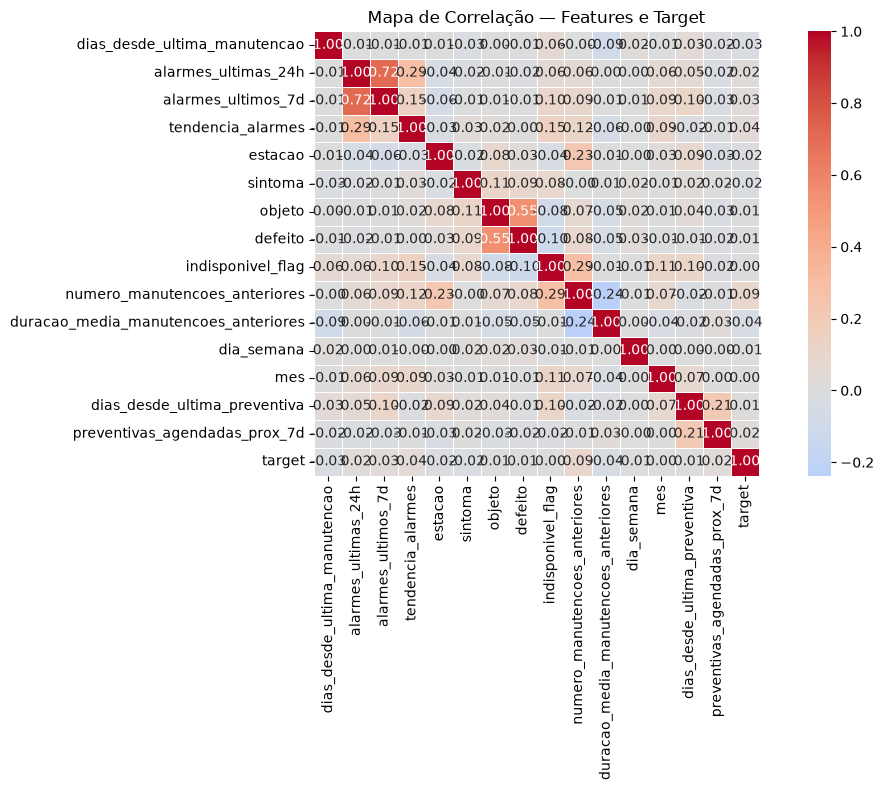

In [24]:
features = df_modelo[colunas_features]
corr_matrix = features.assign(target=df_modelo[coluna_target]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True)
plt.title("Mapa de Correlação — Features e Target")
plt.tight_layout()
plt.show()

## 11. Síntese

Reunindo o que este notebook mostra, do início ao fim:

- O alvo `falha_proximos_7d` é extremamente desbalanceado (98,85% / 1,15%) porque, nos dados disponíveis, falhas tendem a se agrupar no tempo — a maioria das manutenções é seguida por outra dentro de uma semana. Prever a classe rara (estação que "ficou bem" por 7 dias) é o objetivo mais valioso e também o mais difícil.
- O modelo, mesmo com reponderação de classe e busca de hiperparâmetros, consegue apenas um sinal fraco sobre essa classe rara (precisão e recall baixos no teste), e o diagnóstico treino-vs-teste mostra uma queda de desempenho real — o modelo não generaliza tão bem quanto o resultado de treino sugere.
- A investigação sobre falhas muito próximas no tempo não encontrou uma explicação limpa (a flag de reincidência do SAP não cobre a maior parte dos casos), deixando uma dúvida legítima sobre o quão "limpo" é o próprio rótulo que está sendo usado.
- A importância de features e o mapa de correlação, junto com features adicionais testadas ao longo do desenvolvimento (algumas descartadas por não melhorarem o resultado), apontam para uma conclusão consistente: o histórico de manutenção e alarme disponível hoje carrega pouco sinal preditivo direto para antecipar quando uma porta específica vai falhar.

Isso não invalida o esforço — descobrir que o sinal disponível é fraco é, em si, um resultado útil para direcionar o próximo passo, seja coletando um tipo de dado diferente (ex.: leituras de sensor contínuas, em vez de eventos discretos de alarme/manutenção), seja reformulando o problema (por exemplo, prever risco relativo entre estações em vez de um rótulo binário rígido).